# Predicting Purchase Behavior

## Goal
The goal of this project is to create a machine learning model which predicts if a user will complete a purchase on a retail website based on user session data. This model will help improve marketing decisions and overall sales.



In [ ]:
# First I will load the Kaggle "Online Shoppers Purchasing Intention Dataset"

import pandas as pd

from google.colab import files
uploaded = files.upload()
df = pd.read_csv("online_shoppers_intention.csv")

print(df.head())

print("shape:", df.shape)
print(df.isnull().sum())

Saving online_shoppers_intention.csv to online_shoppers_intention (2).csv
   Administrative  Administrative_Duration  Informational  \
0               0                      0.0              0   
1               0                      0.0              0   
2               0                      0.0              0   
3               0                      0.0              0   
4               0                      0.0              0   

   Informational_Duration  ProductRelated  ProductRelated_Duration  \
0                     0.0               1                 0.000000   
1                     0.0               2                64.000000   
2                     0.0               1                 0.000000   
3                     0.0               2                 2.666667   
4                     0.0              10               627.500000   

   BounceRates  ExitRates  PageValues  SpecialDay Month  OperatingSystems  \
0         0.20       0.20         0.0         0.0   Feb      

As you can see, the Kaggle dataset shows individual session data and shows if a user completes a purchase or not. The dataset does not need to be cleaned since there are no missing values. The dataset also does not contain personally identifiable information, which helps limit privacy concerns during analysis.

In [ ]:
# Now I will convert text values into numerical data so that the model can use them

from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()

for col in df.select_dtypes(include="object").columns:
    df[col] = le.fit_transform(df[col])

print("encoding done")

encoding done


# Dashboard for User Behavior and Purchase Analysis

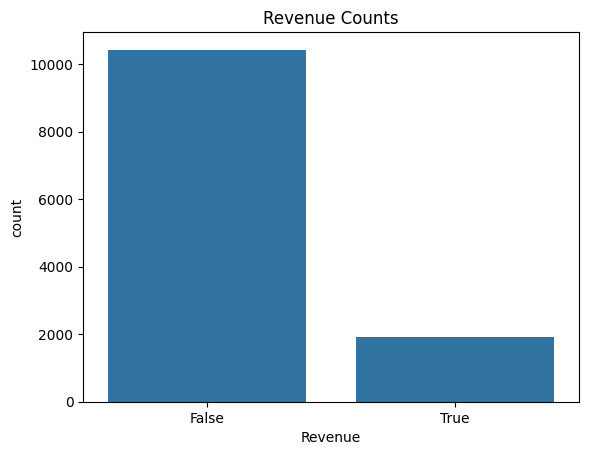

In [ ]:
# Visualization #1- Count Plot for Buyers vs Non-buyers

import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(x=df["Revenue"])
plt.title("Revenue Counts")
plt.show()

The count plot shows that most users on the retail website do not make a purchase. This means that the dataset is imbalanced which may make it harder for the model to pick up on buyers.

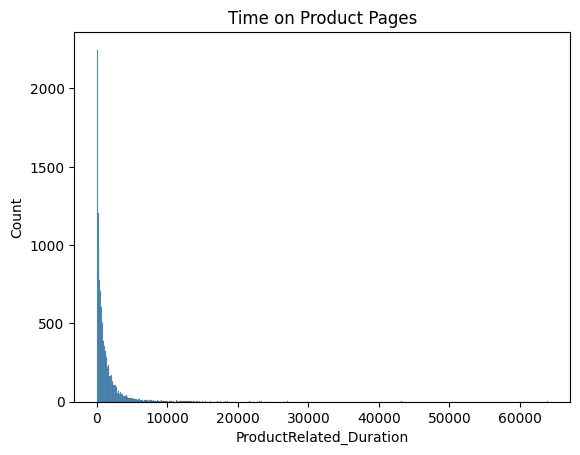

In [ ]:
# Visualization #2- Histogram for User Time on Product Pages
import matplotlib.pyplot as plt
import seaborn as sns

sns.histplot(df["ProductRelated_Duration"])
plt.title("Time on Product Pages")
plt.show()

The histogram shows that users spend different amounts of time on the product pages on the retail website. A higher time may represent more interest in the products.

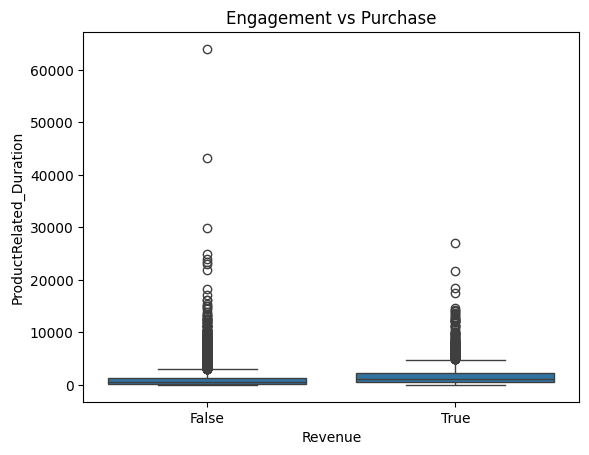

In [ ]:
# Visualization #3- Boxplot for Engagement vs Purchase Behavior

sns.boxplot(x=df["Revenue"], y=df["ProductRelated_Duration"])
plt.title("Engagement vs Purchase")
plt.show()

The boxplot shows that the users who complete a purchase spend more time on product pages than those who don't. This suggests that there may be a relationship between time spent on product pages and purchase behavior.

In [ ]:
# Next I will split the data into training and testing sets so the model is tested on new data rather than just memorizing patterns

from sklearn.model_selection import train_test_split

x = df.drop("Revenue", axis=1)
y = df["Revenue"]

xtrain, xtest, ytrain, ytest = train_test_split(
    x, y, test_size=0.2, random_state=42
)

print("train:", len(xtrain))
print("test:", len(xtest))

train: 9864
test: 2466


In [ ]:
# Next I will train a logistic regression model to predict if a user will make a purchase (yes/no outcome)

from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=10000, solver='liblinear')
lr.fit(xtrain, ytrain)

preds = lr.predict(xtest)

In [ ]:
# Next I will evaluate how well the model performs using accuracy, precision, and recall

from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix

acc = accuracy_score(ytest, preds)
prec = precision_score(ytest, preds)
rec = recall_score(ytest, preds)

print("accuracy:", acc)
print("precision:", prec)
print("recall:", rec)

accuracy: 0.8673965936739659
precision: 0.723404255319149
recall: 0.3309002433090024


The model has an accuracy of 0.87 which means it predicts the outcome most of the time. It has a precision of 0.72 which shows that when the model predicts a purchase it is usually correct. It has recall of 0.34 which means that the model may be missing some users who complete a purchase. The model performs well, however it can be improved to better identify all of the buyers.

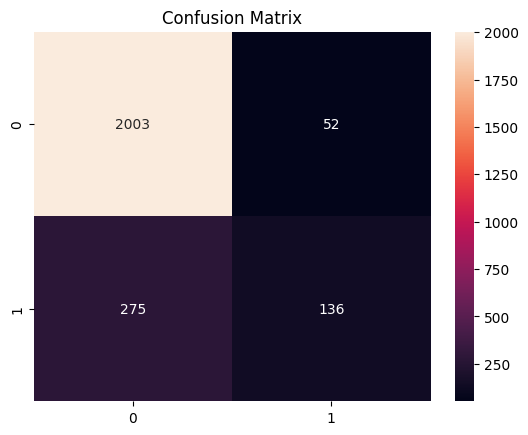

In [ ]:
# Next I will use a confusion matrix to see how the model’s predictions compare to the actual results

cm = confusion_matrix(ytest, preds)

sns.heatmap(cm, annot=True, fmt='d')
plt.title("Confusion Matrix")
plt.show()

The confusion matrix shows that the model predicts non-buyers more accurately than buyers. The model needs to be improved to better identify the customers who are likely to make a purchase.

In [ ]:
# Now I will use an interactive prediction example to test how the model performs
user_index = 5

sample_data = xtest.iloc[[user_index]]

prediction = lr.predict(sample_data)

print("Prediction for User", user_index, ":", prediction[0])
print("Actual Result:", ytest.iloc[user_index])

Prediction for User 5 : False
Actual Result: False


In [ ]:
# Last I will compare predictions with the actual values

results_df = pd.DataFrame({
    "Actual": ytest.values,
    "Prediction": preds
})

print(results_df.head())

   Actual  Prediction
0   False       False
1    True       False
2   False       False
3   False       False
4   False       False


This comparison helps show how well the model is performing and where it can be improved.
This could help a business focus on users who are more likely to buy.